> **You are running this notebook in your browser.**
> 1. **First, press ▶ on the Browser Setup cell directly below** and wait for it to finish before running any other cells.
> 2. Your changes are saved in this browser only — at the end of class, choose **File → Download** to keep a copy of your work.

In [ ]:
# Browser setup (run this cell first): enables web data loading in your browser.
%pip install -q pyodide-http seaborn
import pyodide_http
pyodide_http.patch_all()
print("Browser setup complete — you can run the rest of the notebook now.")


# Welcome to Talking Trees Day 3!

Last time, we learned how the environment and the sapflow of Erisma and Itauba change over the course of a day and throughout the year.

Take a few minutes to go over the key takeaways.


Today, we'll be comparing how *Erisma* and *Itauba* compare to other species in the Amazon during a drought.

---

First things first, let's get our computer set up and ready to code! Press the play button near the Run Setup code block.

In [ ]:
# DO NOT EDIT THIS BLOCK

# @title Run Setup

# Load in the packages/libraries
# Packages and libraries contain functions which will perform certain actions in code
import hashlib
import pandas as pd # to manipulate data
import numpy as np # for mathematical operations
from cycler import cycler
import matplotlib.pyplot as plt # for plotting
import seaborn as sns # for plotting




# Define environmental variables
env_vars = ['temp', 'light', 'rain', 'humidity']

# Define a consistent color palette for variables
variable_colors = {
    'temp': '#a6cee3',
    'light': '#1f78b4',
    'rain': '#b2df8a',
    'humidity': '#33a02c',
    'VPD' : '#fdbf6f',
    'sf.itauba': '#fb9a99',
    'sf.erisma': '#e31a1c',
    'Itauba' : '#fb9a99',
    'Erisma' : '#e31a1c',
    'Other species' : '#fdbf6f'
}





# Load in the custom functions

## Create a function to load in data without worrying about file paths

# Load data directly into Python (into RAM) from public download link.
# - You need to turn the share link that looks like this: https://drive.google.com/file/d/FILE_ID/view?usp=sharing
#   -- ...into a download link that looks like this: https://drive.google.com/uc?export=download&id=FILE_ID
#   -- I.e. start with https://drive.google.com/ , add uc?export=download&id= , then the share-link text between "/d/" and "/view?" (here "FILE_ID").
# Dataset share link: https://drive.google.com/file/d/1GenDfhfqKDPM_AcG8eJyrzOxDuMz7vTL/view?usp=drive_link
# Dataset download URL


def load_data(dataset):
  if dataset == "environment_data_subset":
    url = 'https://amazon-talking-trees.github.io/talking-trees/data/Sapflow_HalfHourly_TTMods_V1.0.csv'
    df = pd.read_csv(url)
    # select only the columns we want to use
    cols = ['date', 'year', 'month', 'hour', 'temp', 'light', 'rain', 'humidity', 'yr.label']
    data_temp = df[cols]
    print("Data Loaded Successfully")
    print(len(data_temp), " rows of data loaded")
    return df[cols]

  elif dataset == "environment_sapflow_data_subset":
    url = 'https://amazon-talking-trees.github.io/talking-trees/data/Sapflow_HalfHourly_TTMods_V1.0.csv'
    df = pd.read_csv(url)
    # select only the columns we want to use
    cols = ['date', 'year', 'month', 'hour', 'temp', 'light', 'rain', 'humidity', 'yr.label', 'sf.itauba', 'sf.erisma']
    data_temp = df[cols]
    print("Data Loaded Successfully")
    print(len(data_temp), " rows of data loaded")
    return df[cols]

  elif dataset == "environment_sapflow_data_all":
    url = 'https://amazon-talking-trees.github.io/talking-trees/data/Sapflow_HalfHourly_TTMods_V1.0.csv'
    df = pd.read_csv(url)
    # select only the columns we want to use
    cols = ['date', 'year', 'month', 'hour', 'temp', 'light', 'rain', 'VPD', 'humidity', 'yr.label', 'sf.itauba', 'sf.erisma']
    data_temp = df[cols]
    print("Data Loaded Successfully")
    print(len(data_temp), " rows of data loaded")
    return df[cols]

  elif dataset == "stomata_data":
    url = "https://amazon-talking-trees.github.io/talking-trees/data/Stomata_Species_prc-250602.csv"
    df = pd.read_csv(url)
    # rename the columns
    df = df[['fam.scr', 'gen.scr', 'sp.scr', 'st.length', 'st.dens']].copy()
    df.rename(columns = {'fam.scr': 'family', 'gen.scr': 'genus', 'sp.scr': 'species'}, inplace = True)
    # Make a 'species category' column
    df['species_category'] = df['species'].apply(lambda x: 'Erisma' if x == 'Erisma uncinatum' else 'Itauba' if x == 'Mezilaurus itauba' else 'Other species')
    # Convert mm to m
    df['st.length'] = df['st.length']/1000
    df['st.dens'] = df['st.dens']*1000*1000
    data_temp = df
    print("Data Loaded Successfully")
    print(len(data_temp), " rows of data loaded")
    return df

  elif dataset == "xylem_data":
    url = 'https://amazon-talking-trees.github.io/talking-trees/data/Xylem_Species_prc-240216.csv'
    df = pd.read_csv(url)
    df = df[['fam.scr', 'gen.scr', 'sp.scr', 'diam.avg', 'area.avg', 'diam.max', 'ves.dens', 'rel.lum.area']].copy()
    df.rename(columns = {'fam.scr': 'family', 'gen.scr': 'genus', 'sp.scr': 'species'}, inplace = True)
    df['species_category'] = df['species'].apply(lambda x: 'Erisma' if x == 'Erisma uncinatum' else 'Itauba' if x == 'Mezilaurus itauba' else 'Other species')
    data_temp = df
    print("Data Loaded Successfully")
    print(len(data_temp), " rows of data loaded")
    return df

  else:
    print("Dataset not found. Please input a valid dataset name.")

  data = df[cols]
  print("Data Loaded Successfully")
  print(len(data), " rows of data loaded")
  return data


## Function to the the monthly summary for environmental data
def get_monthly_summary(data, vars = env_vars) :

  cols = ['year', 'month', 'hour'] + vars
  data = data[cols]

  if 'rain' in data.columns:
    # Do rain first since it doesn't get filtered to daytime values
    dat_mo = data.groupby(['year', 'month'])['rain'].sum().reset_index()

  # isolate daytime values for everything except for rain
  idl = (data['hour'] > 9) & (data['hour'] < 17)

  if 'rain' in data.columns:
    vars = [v for v in vars if v != "rain"] # make sure it's all the variables but rain

  # Group the data so we get averages for each month in each year separately
  dat_mo2 = data.loc[idl].groupby(['year', 'month'])[vars].mean().reset_index()

  # Put rain and the other variables back together in the same table
  if 'rain' in data.columns:
    dat_mo_combo = pd.merge(dat_mo, dat_mo2, how = "right", on = ["year", "month"])
  else:
    dat_mo_combo = dat_mo2


  # Add in the labels for drought condition for each year -- may not need if this column is already in the dataset
  dat_mo_combo['yr_label'] = 'Normal'
  dat_mo_combo.loc[dat_mo_combo['year'] == 2015, 'yr_label'] = 'Drought'
  dat_mo_combo.loc[dat_mo_combo['year'] == 2016, 'yr_label'] = 'Post-Drought'

  return dat_mo_combo


# Plotting function for monthly trends across years
def plot_monthly_data(data, vars = env_vars, years = ['Normal'], xaxis = 'month'):

  # Make our basic plot, with enough subplots for each variable
  fig, axs = plt.subplots(len(vars), 1, sharex=True, figsize=(6, 8))

  # Loop through variables to create plots - this will make one subplot for each variable we put into it
  for i, var in enumerate(vars):
    # Make a title for each plot
      title = f"Monthly average of {var} over the course of a year"
      axs[i].set_title(title)
      # Make a lineplot for each variable, for each year
      sns.lineplot(ax = axs[i], x = xaxis, y = var, data = data[data['yr_label'].isin(years)], hue = "yr_label", legend = True)
      # Add points to each graph
      sns.scatterplot(ax = axs[i], x = xaxis, y = var, data = data[data['yr_label'].isin(years)], hue = "yr_label", legend = False)
      # Shade the wet season
      axs[i].axvspan(1, 7, facecolor = "grey", alpha = 0.2)

  # Create a proxy artist for the wet season label
  wet_season_patch = plt.matplotlib.patches.Rectangle((0,0), 1, 1, facecolor="grey", alpha=0.2, label='Wet Season')

  # Apply a common legend
  handles, labels = axs[0].get_legend_handles_labels()  # Get legend from first plot
  custom_labels = years
  handles.append(wet_season_patch) # Add the wet season patch to the handles
  custom_labels.append('Wet Season') # Add the wet season label

  fig.legend(handles, custom_labels, loc = 'right', title = "Year", bbox_to_anchor = (1.3, 0.5)) # set it on the right side
  for i, fig in enumerate(vars):
    axs[i].get_legend().remove() # Remove the legends from each individual plot
  plt.tight_layout()  # Adjust layout to prevent overlap
  plt.show()



# Function to plot N random days of diurnal data

def graph_diurnals(data, n_days = 6, vars = ['temp', 'light'], title = '') :

  # Subset data and order factor levels to plot in order specificed in env_vars
  # Make sure vars is in the right format

  # Prepare the data for plotting
  # Select all the columns we want
  cols = ['date', 'hour', 'month'] + vars + ['sf.erisma', 'sf.itauba']
  # Pick dates from 2014
  dat_d = pd.melt(data[data['year'] == 2014][cols], id_vars = ['date', 'hour', 'month'])
  dat_d['variable'] = dat_d['variable'].astype('category')
  # Remove all the nighttime data
  dat_final = dat_d[(dat_d['hour'] >= 5) & (dat_d['hour'] <= 20)]

  # Ensure the variables we want to plot are actually in the dat_d dataframe columns
  # This prevents errors if a variable name is mistyped or not present
  valid_vars = [v for v in vars if v in dat_final['variable'].unique()] + ['sf.erisma', 'sf.itauba']
  sub = dat_final[dat_final['variable'].isin(valid_vars)].copy()
  if sub.empty:
      print("Error: No data available for the specified variables and dates.")
      return # Exit the function if there's no data to plot

  # Add a column for the wet and dry season
  sub['season'] = 'dry'
  sub.loc[(sub['month'] >= 1) & (sub['month'] <= 7), 'season'] = 'wet'


  # Pick a random sample of days from the chosen year
  # Half will be from the wet season and half from the dry season
  sub['variable'] = pd.Categorical(sub['variable'], categories = valid_vars)
  sub_wet = sub[sub['season'] == 'wet']
  sub_dry = sub[sub['season'] == 'dry']
  unique_dates_wet = sub_wet['date'].unique()
  unique_dates_dry = sub_dry['date'].unique()
  n_days_dry = round(n_days/2)
  n_days_wet = n_days - n_days_dry
  sampled_dates_wet = np.random.choice(unique_dates_wet, size= n_days_wet, replace=False)
  sampled_dates_dry = np.random.choice(unique_dates_dry, size= n_days_dry, replace=False)
  sub_sampled_days_wet = sub[sub['date'].isin(sampled_dates_wet)].copy()
  sub_sampled_days_dry = sub[sub['date'].isin(sampled_dates_dry)].copy()
  # Ensure sub_sampled_days only contains the selected dates and variables
  sub_sampled_days_wet = sub_sampled_days_wet[sub_sampled_days_wet['variable'].isin(valid_vars)]
  sub_sampled_days_dry = sub_sampled_days_dry[sub_sampled_days_dry['variable'].isin(valid_vars)]
  # Merge the wet and the dry back together
  sub_sampled_days = pd.concat([sub_sampled_days_wet, sub_sampled_days_dry])

  # Determine the layout of the subplots: columns = dates, rows = variables

  # Separate the sf.itauba and sf.erisma variables to plot them together
  sf_vars = ['sf.itauba', 'sf.erisma']
  other_vars = [v for v in valid_vars if v not in sf_vars]
  plot_vars = other_vars + ['sapflow'] # Add a placeholder for the combined sapflow plot

  n_cols = len(sub_sampled_days['date'].unique())
  n_rows = len(plot_vars)
  fig, axs = plt.subplots(n_rows, n_cols, sharex=True, figsize=(12, 10))

  # Ensure all the y axes are on the same scale per varaible
  # Make this the same for all days, not just the ones selected
  y_limits = {
    var: (
      dat_final[dat_final['variable'] == var]['value'].min(),
      dat_final[dat_final['variable'] == var]['value'].max()
    )
    for var in valid_vars
  }

  # Make plots for each varable-date combination
  for i, var in enumerate(plot_vars):
    for j, date in enumerate(sub_sampled_days['date'].unique()):
      ax = axs[i,j]
      if var == 'sapflow':
          subset = sub_sampled_days[(sub_sampled_days['date'] == date) & (sub_sampled_days['variable'].isin(sf_vars))]
          sns.lineplot(data=subset, x='hour', y='value', ax=ax, hue='variable', legend=False, palette=variable_colors) # Remove legend from subplot
          # Set y-axis limits for sapflow variables
          min_sf = min(y_limits['sf.itauba'][0], y_limits['sf.erisma'][0])
          max_sf = max(y_limits['sf.itauba'][1], y_limits['sf.erisma'][1])
          ax.set_ylim(min_sf, max_sf)
      else:
          subset = sub_sampled_days[(sub_sampled_days['date'] == date) & (sub_sampled_days['variable'] == var)]
          sns.lineplot(data=subset, x = 'hour', y = 'value', ax=ax, hue = 'variable', legend = False, palette=variable_colors) # Remove legend from subplot
          ax.set_ylim(y_limits[var])

  # Set the axes labels
  for i, var in enumerate(plot_vars):
      label = 'Sapflow' if var == 'sapflow' else var
      axs[i, 0].set_ylabel(f'{label}', fontsize=12, rotation=0, labelpad=50)
  for j, date in enumerate(sub_sampled_days['date'].unique()):
    axs[0, j].set_title(f'{date}', fontsize=12, pad = 20)

  # Add a single legend for the entire figure
  # Get handles and labels for all variables
  all_handles = []
  all_labels = []
  for var in other_vars:
      # Create a proxy artist for each individual variable
      all_handles.append(plt.Line2D([0], [0], color=variable_colors[var], lw=2))
      all_labels.append(var)

  # Create proxy artists for the sapflow variables
  for sf_var in sf_vars:
      all_handles.append(plt.Line2D([0], [0], color=variable_colors[sf_var], lw=2))
      all_labels.append(sf_var)

  fig.legend(all_handles, all_labels, loc='right', title='Variable', bbox_to_anchor=(1.2, 0.5))

  plt.tight_layout()
  plt.show()


## Custom function for calculating the stomatal conductive capacity
def calc_gw_max(data, length = 'st.length', density = 'st.dens') :
    length = data[length]
    density = data[density]
    pi = 3.14159265359
    d = 0.0000249
    v = 0.0224
    A = 0.12 * length * length/2
    l = length/4
    gw_max = (d * (density/v)) * (A / (l + (0.5 * ((pi * A)**0.5))))
    return gw_max



print("Setup Run Correctly!")



Setup Run Correctly!


Today, we'll be taking a look at some features of the water moving structures called **xylem**. We'll need to load in our new dataset, called **xylem_data**, using the load_data() function. Once we do that, we'll take a look at the first 5 rows of the data table. We'll name our new data table 'xylem'.

***  Should we have them type in the code today, or no? Perhaps they should just fill in the arguments?***

In [ ]:
# Read in the xylem data
###### I think the arguments can be left blank for students
xylem = load_data(dataset = "xylem_data")

# Look at the first 5 rows of the data
xylem.head(5)


#### Find some graceful way to describe what the columns mean. I can rename them if that's helpful,
#### but I think they're straightforward enough for students to know what they indicate, so long as we have descriptors


# diam.avg = average xylem vessel diameter
# area.avg = average total area of the xylem (?) ## cut?
# diam.max = maximum diameter of xylem vessels ## cut?
# ves.dens = xylem vessel density per area of wood
# rel.lumen.area = fraction of the wood area that is sapwood (?) ## cut?

,family,genus,species,diam.avg,area.avg,diam.max,ves.dens,rel.lum.area,species_category
0,Fabaceae,Abarema,Abarema mataybifolia,0.056734,0.002539,0.086057,16.765250,0.039553,Other species
1,Annonaceae,Anaxagorea,Anaxagorea dolichocarpa,0.046402,0.001715,0.066509,24.049571,0.033147,Other species
2,Euphorbiaceae,Aparisthmium,Aparisthmium cordatum,0.059975,0.002827,0.086792,21.752724,0.061414,Other species
3,Moraceae,Brosimum,Brosimum parinarioides,0.085767,0.005887,0.117253,8.670134,0.049507,Other species
4,Fabaceae,Chamaecrista,Chamaecrista scleroxylon,0.051427,0.002100,0.070926,12.876073,0.026284,Other species


In [ ]:
# Now we need to make a special label for Erisma and Itauba compared to the other species
# Here, I'm telling the computer to make a new column in our table called
# 'species_category' which will have 'Erisma' if the species is 'Erisma
# uncinatum', Itauba if the species is 'Mezilaurus itauba', and all other
# species will be 'Other species'

# Feel free to take a look at the code or simply press the play button to move on!

xylem['species_category'] = xylem['species'].apply(lambda x: 'Erisma' if x == 'Erisma uncinatum' else 'Itauba' if x == 'Mezilaurus itauba' else 'Other species')
xylem.head(10)

#### I moved this into the load_data() function. Can remove this block entirely

,family,genus,species,diam.avg,area.avg,diam.max,ves.dens,rel.lum.area,species_category
0,Fabaceae,Abarema,Abarema mataybifolia,0.056734,0.002539,0.086057,16.765250,0.039553,Other species
1,Annonaceae,Anaxagorea,Anaxagorea dolichocarpa,0.046402,0.001715,0.066509,24.049571,0.033147,Other species
2,Euphorbiaceae,Aparisthmium,Aparisthmium cordatum,0.059975,0.002827,0.086792,21.752724,0.061414,Other species
3,Moraceae,Brosimum,Brosimum parinarioides,0.085767,0.005887,0.117253,8.670134,0.049507,Other species
4,Fabaceae,Chamaecrista,Chamaecrista scleroxylon,0.051427,0.002100,0.070926,12.876073,0.026284,Other species
5,Rubiaceae,Chimarrhis,Chimarrhis turbinata,0.038780,0.001194,0.055276,31.772972,0.037620,Other species
6,Lecythidaceae,Couratari,Couratari oblongifolia,0.061860,0.003005,0.095123,19.588081,0.058870,Other species
7,Annonaceae,Duguetia,Duguetia surinamensis,0.028769,0.000650,0.039151,96.334823,0.062622,Other species
8,Vochysiaceae,Erisma,Erisma uncinatum,0.065314,0.003464,0.096757,9.066858,0.028740,Erisma
9,Lecythidaceae,Eschweilera,Eschweilera ovata,0.047697,0.001787,0.070754,16.269881,0.029070,Other species


Now that we have our data, let's make some graphs! First, we'll take a look at the average xylem diameter for all species.

### Plotting Xylem Diameter

We'll make a box and whisker plot (or a boxplot) using the sns.boxplot() function. There's a lot of different arguments we can use!

We'll need to specify the data table (data), the y-axis (y), and the color of the boxplot (hue). We'll add some additional arguemnts to make it look nice which are described in the coding block below.

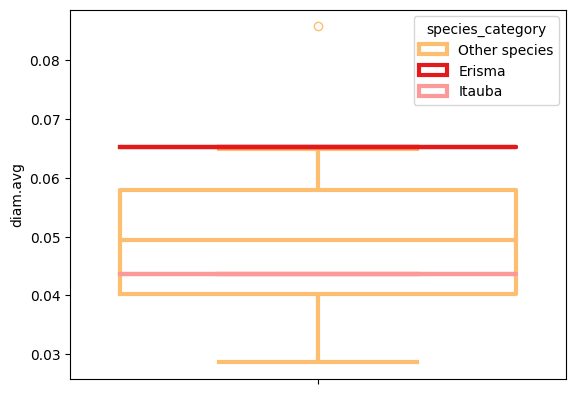

In [ ]:
# Coding tip! When you are specifying the name of a column from your data
# table in a function, be sure to write it in quotes ''

sns.boxplot( # making a boxplot
             data = xylem, # The data where we are going to get the measurements
             y = 'diam.avg', # The measurment we want to look at
             hue = 'species_category', # Color the plot by species category
             palette = variable_colors, # use our normal color scheme
             dodge = False, # Make it so everything plots on top of eachother
             linewidth = 3, # Make the lines a little bigger
             fill = False) # Remove the fill so we can see the lines better
plt.show()

What do you notice about the average xylem diameter? ***other learning questions here***

### Plotting Vessel Density

Now, let's take a look at the vessel density. This column is called 'ves.dens' in your data table.

In [ ]:
# Edit the code to look at the vessel density!

# Vessel Density
sns.boxplot( # making a boxplot
             data = , # The data where we are going to get the measurements
             y = , # The measurment we want to look at
             hue = , # Color the plot by species category
             palette = variable_colors, # use our normal color scheme
             dodge = False, # Make it so everything plots on top of eachother
             linewidth = 3, # Make the lines a little bigger
             fill = False) # Remove the fill so we can see the lines better
plt.show()

SyntaxError: expected argument value expression (ipython-input-3112455295.py, line 5)

What do you notice about the vessel density? ***other learning questions here***

Neither vessel size or density alone tell us about how much water is moving through a plant. We have to look at their impact together. We can calculate the **relative conductive capacity** or the maximum amount of water a plant can move through its xylem at once.

### Calculating and Plotting Relative Conductive Capacity

We calculate the relative conductive capacity by multiplying the vessel density by the xylem diameter raised to the fourth power:

conductive capacity = density * diameter<sup>4</sup>


In [ ]:
# Calculate the relative conductive capacity
# We'll make a new column in xylem called 'rel.cond'
# The value will be the density times the diameter to the fourth power

# Feel free to study the code or just press play to move on!
xylem['rel.cond'] = xylem['ves.dens'] * xylem['diam.avg']**4
xylem.head(5)

,family,genus,species,diam.avg,area.avg,diam.max,ves.dens,rel.lum.area,species_category,rel.cond
0,Fabaceae,Abarema,Abarema mataybifolia,0.056734,0.002539,0.086057,16.765250,0.039553,Other species,0.000174
1,Annonaceae,Anaxagorea,Anaxagorea dolichocarpa,0.046402,0.001715,0.066509,24.049571,0.033147,Other species,0.000111
2,Euphorbiaceae,Aparisthmium,Aparisthmium cordatum,0.059975,0.002827,0.086792,21.752724,0.061414,Other species,0.000281
3,Moraceae,Brosimum,Brosimum parinarioides,0.085767,0.005887,0.117253,8.670134,0.049507,Other species,0.000469
4,Fabaceae,Chamaecrista,Chamaecrista scleroxylon,0.051427,0.002100,0.070926,12.876073,0.026284,Other species,0.000090


Finally, let's plot the relative conductive capacity!

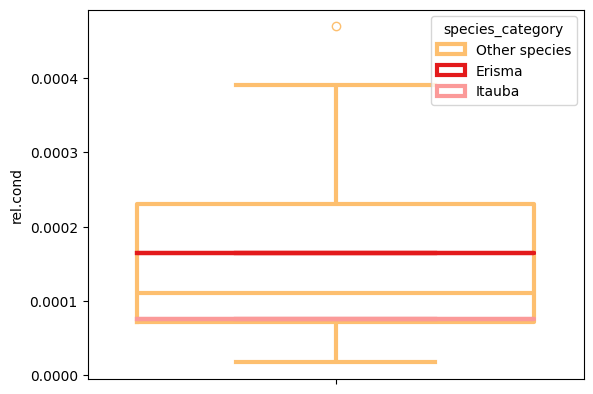

In [ ]:
# Relative conductive capacity
sns.boxplot( # making a boxplot
             data = xylem, # The data where we are going to get the measurements
             y = 'rel.cond', # The measurment we want to look at
             hue = 'species_category', # Color the plot by species category
             palette = variable_colors, # use our normal color scheme
             dodge = False, # Make it so everything plots on top of eachother
             linewidth = 3, # Make the lines a little bigger
             fill = False) # Remove the fill so we can see the lines better
plt.show()

What do you notice about the relative conductive capacity? ***other learning questions here***

Feel free to look at any of the other measurements in the data table! (Python will only show you the *last* plot made in a coding block, so put each new plot in its own block)